# Visualizaciones: tipos y algoritmos de Machine Learning

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from sklearn.datasets import make_blobs, make_classification
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
import os

OUT = '.'
os.makedirs(OUT, exist_ok=True)
np.random.seed(42)

DARK_BG   = '#0d1117'
PANEL_BG  = '#161b22'
BLUE      = '#388bfd'
ORANGE    = '#f0883e'
GREEN     = '#56d364'
RED       = '#ff7b72'
PURPLE    = '#bc8cff'
GRAY      = '#8b949e'
WHITE     = '#e6edf3'

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.facecolor': PANEL_BG, 'figure.facecolor': DARK_BG,
                     'axes.labelcolor': WHITE, 'xtick.color': GRAY, 'ytick.color': GRAY,
                     'text.color': WHITE, 'axes.edgecolor': '#30363d', 'grid.color': '#21262d'})
print('Setup OK')

Setup OK


## Gráfico 1 — Tipos de ML (mapa conceptual)

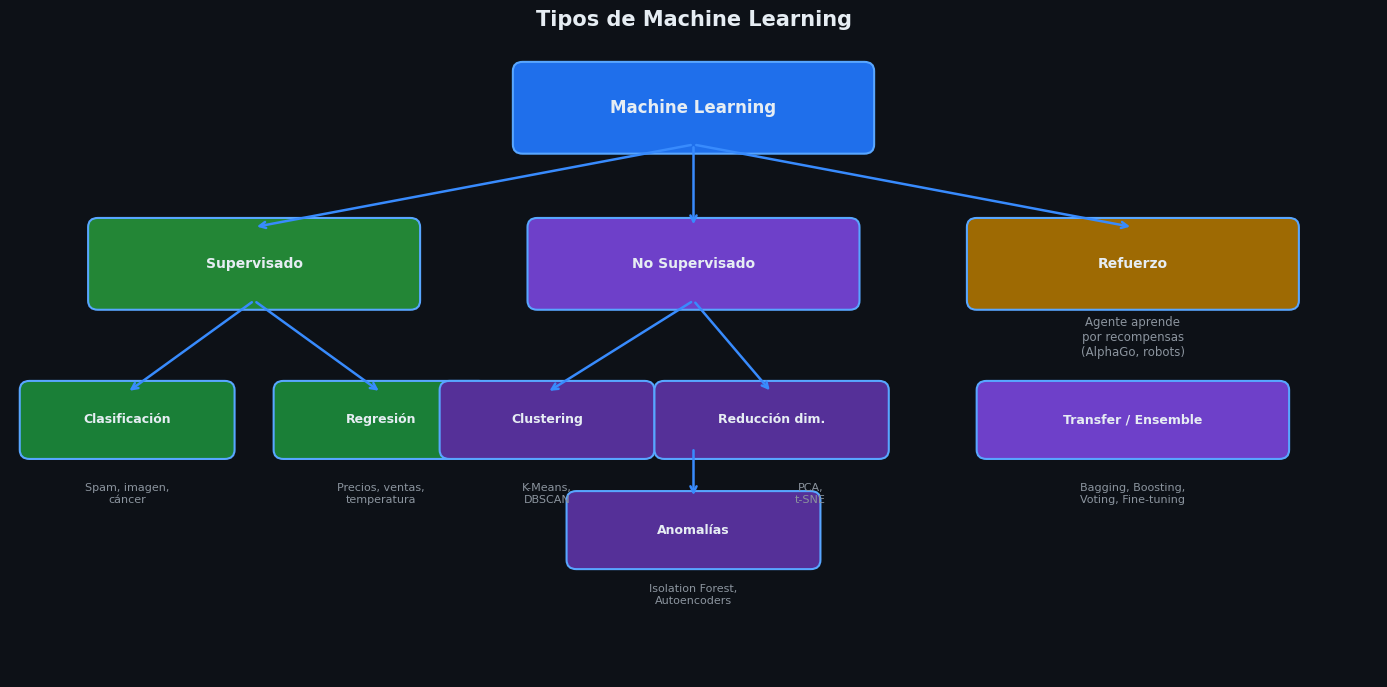

Guardado: 01_tipos_ml.png


In [2]:
fig, ax = plt.subplots(figsize=(14, 7))
ax.set_xlim(0, 14)
ax.set_ylim(0, 7)
ax.axis('off')
ax.set_title('Tipos de Machine Learning', color=WHITE, fontsize=15, fontweight='bold')

def box(ax, x, y, w, h, text, fc, ec='#58a6ff', fs=10):
    r = mpatches.FancyBboxPatch((x-w/2, y-h/2), w, h,
        boxstyle='round,pad=0.1', facecolor=fc, edgecolor=ec, linewidth=1.5)
    ax.add_patch(r)
    ax.text(x, y, text, ha='center', va='center', color=WHITE, fontsize=fs, fontweight='bold')

def arrow(ax, x1, y1, x2, y2, color=BLUE):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle='->', color=color, lw=1.8))

# Root
box(ax, 7, 6.2, 3.5, 0.8, 'Machine Learning', '#1f6feb', fs=12)

# Level 1
box(ax, 2.5, 4.5, 3.2, 0.8, 'Supervisado', '#238636')
box(ax, 7,   4.5, 3.2, 0.8, 'No Supervisado', '#6e40c9')
box(ax, 11.5,4.5, 3.2, 0.8, 'Refuerzo', '#9e6a03')

arrow(ax, 7, 5.8, 2.5, 4.9)
arrow(ax, 7, 5.8, 7,   4.9)
arrow(ax, 7, 5.8, 11.5,4.9)

# Supervised children
box(ax, 1.2, 2.8, 2.0, 0.65, 'Clasificación', '#1a7f37', fs=9)
box(ax, 3.8, 2.8, 2.0, 0.65, 'Regresión',     '#1a7f37', fs=9)
arrow(ax, 2.5, 4.1, 1.2, 3.1)
arrow(ax, 2.5, 4.1, 3.8, 3.1)

ax.text(1.2, 1.9, 'Spam, imagen,\ncáncer', ha='center', color=GRAY, fontsize=8)
ax.text(3.8, 1.9, 'Precios, ventas,\ntemperatura', ha='center', color=GRAY, fontsize=8)

# Unsupervised children
box(ax, 5.5, 2.8, 2.0, 0.65, 'Clustering',    '#553098', fs=9)
box(ax, 7.8, 2.8, 2.2, 0.65, 'Reducción dim.','#553098', fs=9)
box(ax, 7,   1.6, 2.4, 0.65, 'Anomalías',     '#553098', fs=9)
arrow(ax, 7, 4.1, 5.5, 3.1)
arrow(ax, 7, 4.1, 7.8, 3.1)
arrow(ax, 7, 2.5, 7,   1.95)

ax.text(5.5, 1.9, 'K-Means,\nDBSCAN', ha='center', color=GRAY, fontsize=8)
ax.text(8.2, 1.9, 'PCA,\nt-SNE', ha='center', color=GRAY, fontsize=8)
ax.text(7, 0.8, 'Isolation Forest,\nAutoencoders', ha='center', color=GRAY, fontsize=8)

# Reinforcement
ax.text(11.5, 3.5, 'Agente aprende\npor recompensas\n(AlphaGo, robots)', ha='center', color=GRAY, fontsize=8.5)

# Extras
box(ax, 11.5, 2.8, 3.0, 0.65, 'Transfer / Ensemble', '#6e40c9', fs=9)
ax.text(11.5, 1.9, 'Bagging, Boosting,\nVoting, Fine-tuning', ha='center', color=GRAY, fontsize=8)

plt.tight_layout()
plt.savefig(f'{OUT}/01_tipos_ml.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 01_tipos_ml.png')

## Gráfico 2 — Regresión Lineal paso a paso

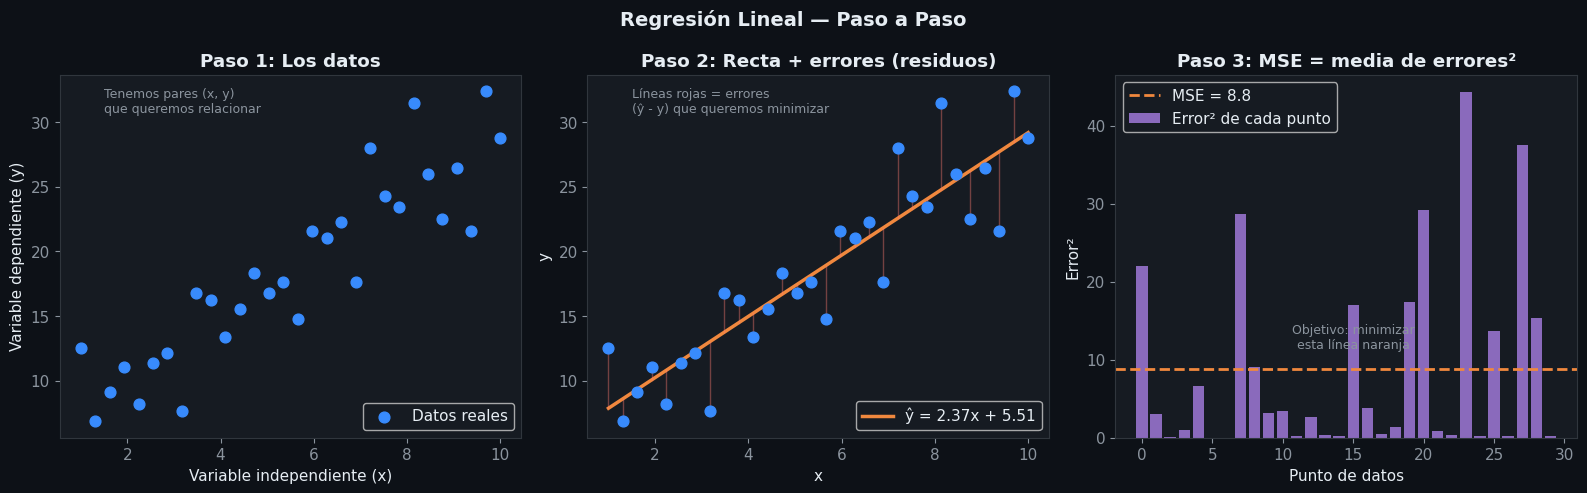

Guardado: 02_regresion_lineal.png


In [3]:
np.random.seed(7)
X = np.linspace(1, 10, 30)
y = 2.5 * X + 5 + np.random.normal(0, 3, 30)
X_fit = X.reshape(-1,1)

model = LinearRegression().fit(X_fit, y)
y_pred = model.predict(X_fit)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Step 1: datos
ax = axes[0]
ax.scatter(X, y, color=BLUE, s=60, zorder=3, label='Datos reales')
ax.set_title('Paso 1: Los datos', color=WHITE, fontweight='bold')
ax.set_xlabel('Variable independiente (x)')
ax.set_ylabel('Variable dependiente (y)')
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE)
ax.text(1.5, max(y)*0.95, 'Tenemos pares (x, y)\nque queremos relacionar', 
        color=GRAY, fontsize=9)

# Step 2: recta ajustada + residuos
ax = axes[1]
ax.scatter(X, y, color=BLUE, s=60, zorder=3)
ax.plot(X, y_pred, color=ORANGE, linewidth=2.5, label=f'ŷ = {model.coef_[0]:.2f}x + {model.intercept_:.2f}')
for xi, yi, ypi in zip(X, y, y_pred):
    ax.plot([xi, xi], [yi, ypi], color=RED, alpha=0.4, linewidth=1)
ax.set_title('Paso 2: Recta + errores (residuos)', color=WHITE, fontweight='bold')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE)
ax.text(1.5, max(y)*0.95, 'Líneas rojas = errores\n(ŷ - y) que queremos minimizar',
        color=GRAY, fontsize=9)

# Step 3: MSE visual
ax = axes[2]
residuos = y - y_pred
ax.bar(range(len(residuos)), residuos**2, color=PURPLE, alpha=0.7, label='Error² de cada punto')
mse = np.mean(residuos**2)
ax.axhline(mse, color=ORANGE, linestyle='--', linewidth=2, label=f'MSE = {mse:.1f}')
ax.set_title('Paso 3: MSE = media de errores²', color=WHITE, fontweight='bold')
ax.set_xlabel('Punto de datos')
ax.set_ylabel('Error²')
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE)
ax.text(len(residuos)*0.5, mse*1.3, 'Objetivo: minimizar\nesta línea naranja', 
        ha='center', color=GRAY, fontsize=9)

plt.suptitle('Regresión Lineal — Paso a Paso', color=WHITE, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/02_regresion_lineal.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 02_regresion_lineal.png')

## Gráfico 3 — Función Sigmoide (Regresión Logística)

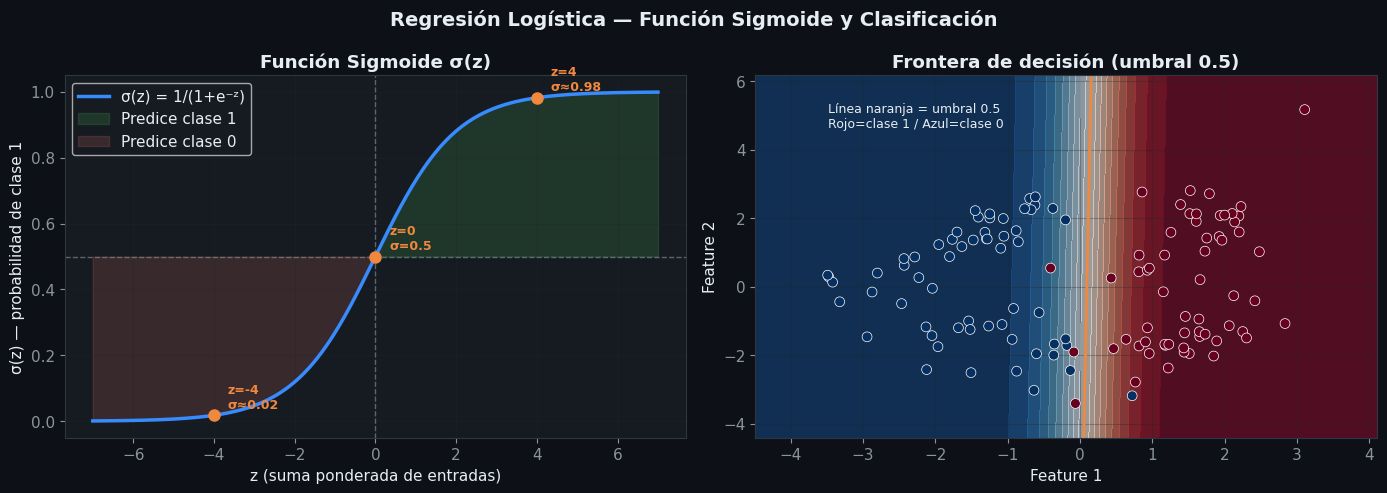

Guardado: 03_sigmoide_logistica.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sigmoide
ax = axes[0]
z = np.linspace(-7, 7, 300)
sigma = 1 / (1 + np.exp(-z))

ax.plot(z, sigma, color=BLUE, linewidth=2.5, label='σ(z) = 1/(1+e⁻ᶻ)')
ax.axhline(0.5, color=GRAY, linestyle='--', linewidth=1, alpha=0.6)
ax.axvline(0, color=GRAY, linestyle='--', linewidth=1, alpha=0.6)
ax.fill_between(z, sigma, 0.5, where=(sigma > 0.5), alpha=0.15, color=GREEN, label='Predice clase 1')
ax.fill_between(z, sigma, 0.5, where=(sigma <= 0.5), alpha=0.15, color=RED, label='Predice clase 0')

# Puntos clave
for zv, sv, label in [(-4, 0.018, 'z=-4\nσ≈0.02'), (0, 0.5, 'z=0\nσ=0.5'), (4, 0.982, 'z=4\nσ≈0.98')]:
    ax.plot(zv, sv, 'o', color=ORANGE, markersize=8, zorder=5)
    ax.annotate(label, (zv, sv), textcoords='offset points', xytext=(10, 5),
                color=ORANGE, fontsize=9, fontweight='bold')

ax.set_title('Función Sigmoide σ(z)', color=WHITE, fontweight='bold')
ax.set_xlabel('z (suma ponderada de entradas)')
ax.set_ylabel('σ(z) — probabilidad de clase 1')
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE)
ax.set_ylim(-0.05, 1.05)
ax.grid(True, alpha=0.3)

# Clasificación logística en 2D
ax = axes[1]
X_cls, y_cls = make_classification(n_samples=120, n_features=2, n_redundant=0,
                                    n_informative=2, random_state=42, class_sep=1.5)
clf = LogisticRegression().fit(X_cls, y_cls)

xx, yy = np.meshgrid(np.linspace(X_cls[:,0].min()-1, X_cls[:,0].max()+1, 200),
                     np.linspace(X_cls[:,1].min()-1, X_cls[:,1].max()+1, 200))
Z = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:,1].reshape(xx.shape)

ax.contourf(xx, yy, Z, levels=20, cmap='RdBu_r', alpha=0.6)
ax.contour(xx, yy, Z, levels=[0.5], colors=[ORANGE], linewidths=2)
sc = ax.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, cmap='RdBu_r', 
                edgecolors='white', s=50, linewidths=0.5, zorder=4)
ax.set_title('Frontera de decisión (umbral 0.5)', color=WHITE, fontweight='bold')
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.text(X_cls[:,0].min(), X_cls[:,1].max()*0.9, 'Línea naranja = umbral 0.5\nRojo=clase 1 / Azul=clase 0',
        color=WHITE, fontsize=9)
ax.grid(True, alpha=0.3)

plt.suptitle('Regresión Logística — Función Sigmoide y Clasificación', color=WHITE, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/03_sigmoide_logistica.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 03_sigmoide_logistica.png')

## Gráfico 4 — K-Means paso a paso (el más importante de RA4)

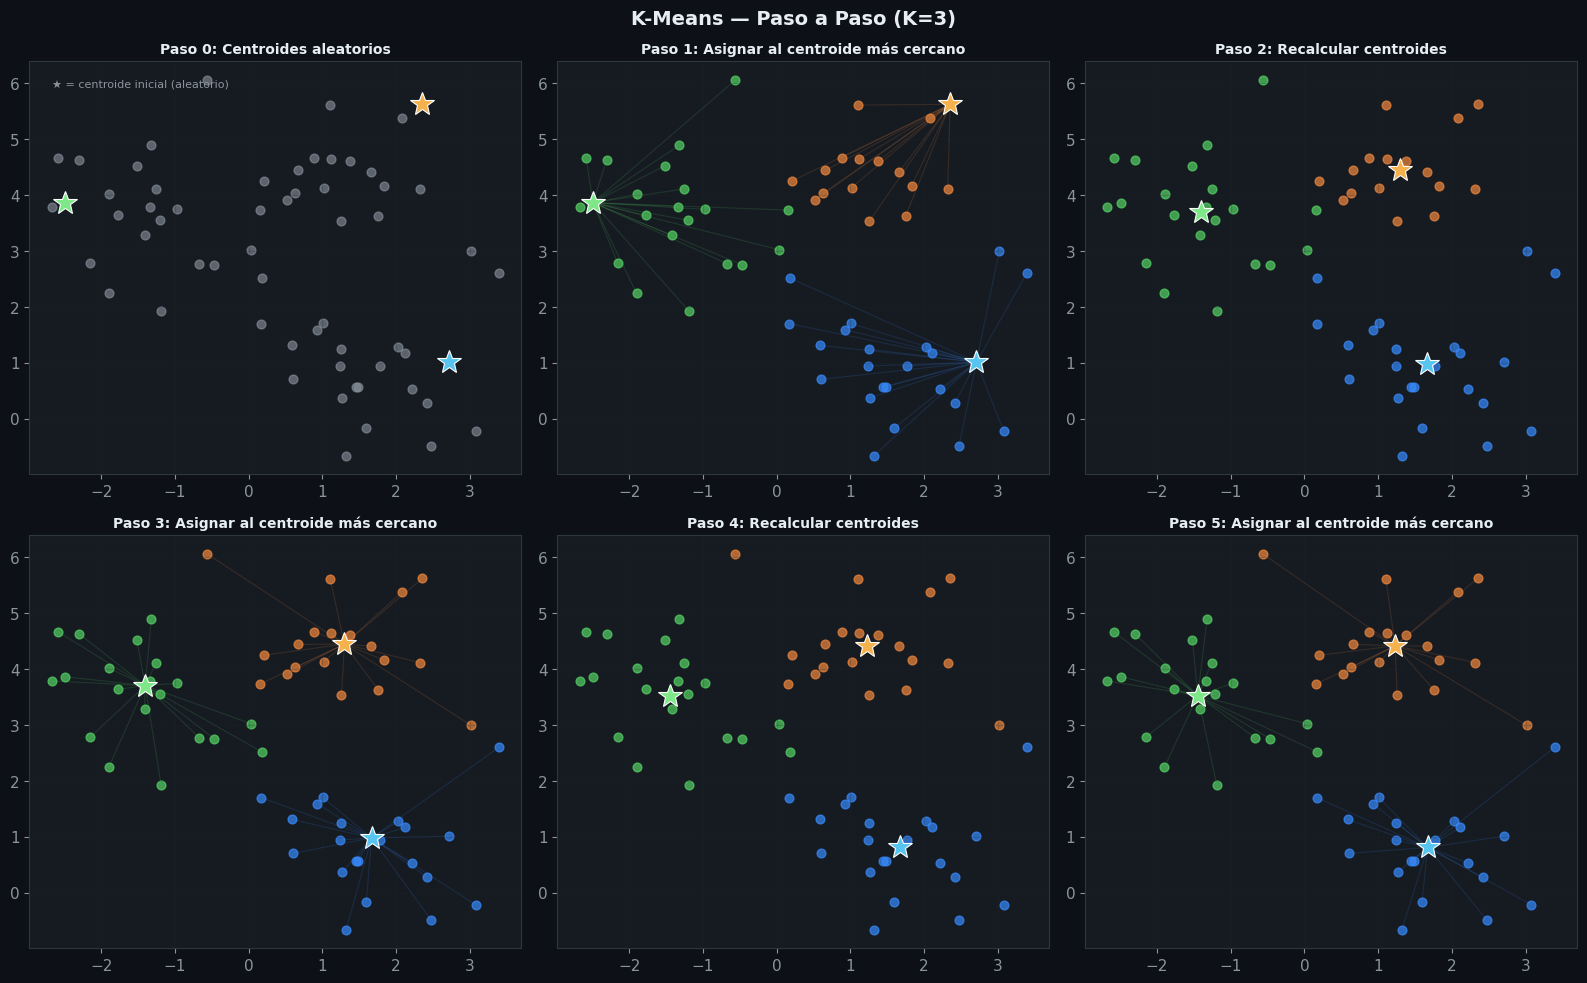

Guardado: 04_kmeans_pasos.png


In [5]:
np.random.seed(0)
X_km, _ = make_blobs(n_samples=60, centers=3, cluster_std=0.9, random_state=0)

# Manual K-Means 3 iteraciones
def assign_clusters(X, centroids):
    dists = np.array([[np.linalg.norm(x - c) for c in centroids] for x in X])
    return np.argmin(dists, axis=1)

def update_centroids(X, labels, k):
    return np.array([X[labels == i].mean(axis=0) for i in range(k)])

K = 3
centroids = X_km[np.random.choice(len(X_km), K, replace=False)]
steps = []
steps.append(('Paso 0: Centroides aleatorios', centroids.copy(), np.zeros(len(X_km), dtype=int)))

for iteration in range(1, 4):
    labels = assign_clusters(X_km, centroids)
    steps.append((f'Paso {2*iteration-1}: Asignar al centroide más cercano', centroids.copy(), labels.copy()))
    centroids = update_centroids(X_km, labels, K)
    steps.append((f'Paso {2*iteration}: Recalcular centroides', centroids.copy(), labels.copy()))

CLUSTER_COLORS = [BLUE, ORANGE, GREEN]
CENTROID_COLORS = ['#58c5f0', '#f5b14c', '#7ee787']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (title, centroids_step, labels_step) in enumerate(steps[:6]):
    ax = axes[i]
    
    if i == 0:
        ax.scatter(X_km[:,0], X_km[:,1], color=GRAY, s=40, alpha=0.6, label='Puntos (sin asignar)')
    else:
        for k in range(K):
            mask = labels_step == k
            ax.scatter(X_km[mask,0], X_km[mask,1], color=CLUSTER_COLORS[k], s=40, alpha=0.7,
                      label=f'Clúster {k+1}')
            # Draw lines from points to centroids on assign steps
            if 'Asignar' in title:
                for pt in X_km[mask]:
                    ax.plot([pt[0], centroids_step[k,0]], [pt[1], centroids_step[k,1]],
                           color=CLUSTER_COLORS[k], alpha=0.15, linewidth=0.8)
    
    # Centroids
    for k in range(K):
        ax.plot(*centroids_step[k], '*', color=CENTROID_COLORS[k], markersize=18,
               markeredgecolor='white', markeredgewidth=0.8, zorder=5)
    
    ax.set_title(title, color=WHITE, fontweight='bold', fontsize=10)
    ax.grid(True, alpha=0.2)
    if i == 0:
        ax.text(X_km[:,0].min(), X_km[:,1].max()*0.98,
                '★ = centroide inicial (aleatorio)', color=GRAY, fontsize=8)

plt.suptitle('K-Means — Paso a Paso (K=3)', color=WHITE, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/04_kmeans_pasos.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 04_kmeans_pasos.png')

## Gráfico 5 — KNN paso a paso

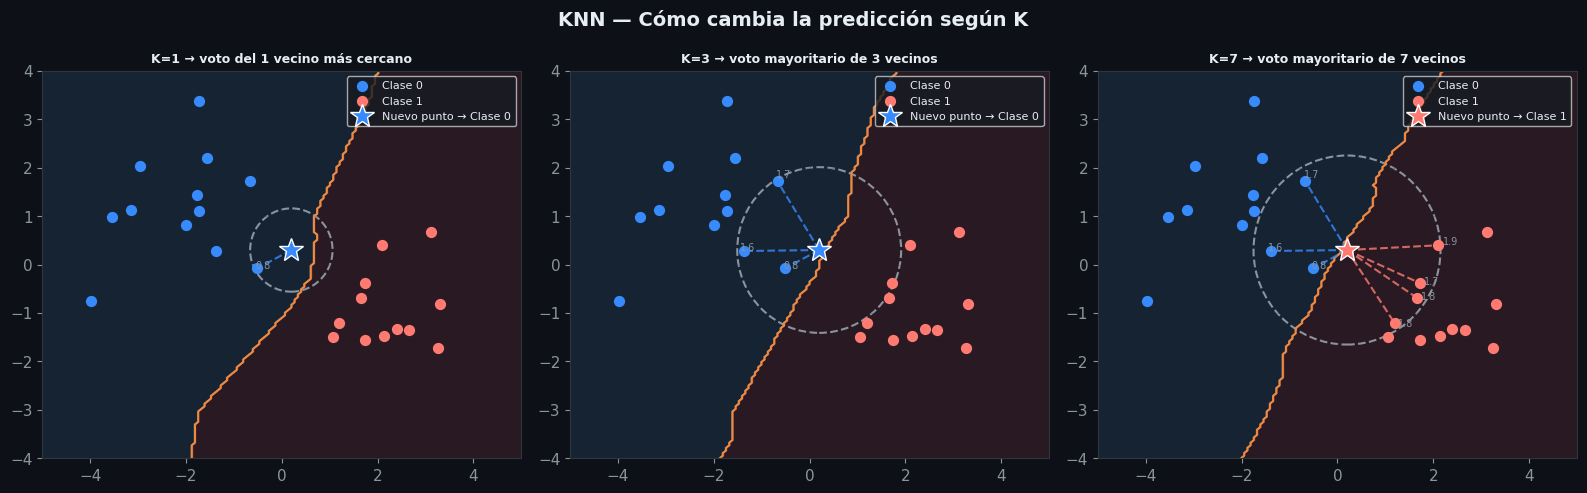

Guardado: 05_knn_pasos.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Dataset sencillo 2 clases
np.random.seed(10)
class0 = np.random.randn(12, 2) + [-2, 1]
class1 = np.random.randn(12, 2) + [2, -1]
X_knn = np.vstack([class0, class1])
y_knn = np.array([0]*12 + [1]*12)
new_point = np.array([0.2, 0.3])  # Punto a clasificar

K_vals = [1, 3, 7]
titles = ['K=1 → voto del 1 vecino más cercano',
          'K=3 → voto mayoritario de 3 vecinos',
          'K=7 → voto mayoritario de 7 vecinos']

for ax, k, title in zip(axes, K_vals, titles):
    # Compute distances
    dists = np.linalg.norm(X_knn - new_point, axis=1)
    k_idx = np.argsort(dists)[:k]
    
    # Background prediction
    clf = KNeighborsClassifier(n_neighbors=k).fit(X_knn, y_knn)
    xx, yy = np.meshgrid(np.linspace(-5,5,150), np.linspace(-4,4,150))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.15, cmap='RdBu_r')
    ax.contour(xx, yy, Z, levels=[0.5], colors=[ORANGE], linewidths=1.5)
    
    # Data points
    ax.scatter(class0[:,0], class0[:,1], color=BLUE, s=50, zorder=3, label='Clase 0')
    ax.scatter(class1[:,0], class1[:,1], color=RED,  s=50, zorder=3, label='Clase 1')
    
    # Draw circles to K neighbors
    circle_r = dists[k_idx[-1]] + 0.05
    circle = plt.Circle(new_point, circle_r, color=GRAY, fill=False, linestyle='--', linewidth=1.5)
    ax.add_patch(circle)
    
    # Lines to neighbors
    for idx in k_idx:
        c = BLUE if y_knn[idx]==0 else RED
        ax.plot([new_point[0], X_knn[idx,0]], [new_point[1], X_knn[idx,1]], 
               color=c, linewidth=1.5, alpha=0.8, linestyle='--')
        ax.text(X_knn[idx,0]*1.05, X_knn[idx,1]*1.05, f'{dists[idx]:.1f}', 
               color=GRAY, fontsize=7)
    
    # New point
    votes = y_knn[k_idx]
    pred = int(np.round(votes.mean()))
    pc = BLUE if pred == 0 else RED
    ax.plot(*new_point, '*', color=pc, markersize=18, markeredgecolor='white', zorder=6,
           label=f'Nuevo punto → Clase {pred}')
    
    ax.set_title(title, color=WHITE, fontweight='bold', fontsize=9)
    ax.set_xlim(-5, 5)
    ax.set_ylim(-4, 4)
    ax.legend(facecolor=PANEL_BG, labelcolor=WHITE, fontsize=8)
    ax.grid(True, alpha=0.2)

plt.suptitle('KNN — Cómo cambia la predicción según K', color=WHITE, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/05_knn_pasos.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 05_knn_pasos.png')

## Gráfico 6 — Árbol de Decisión (visual)

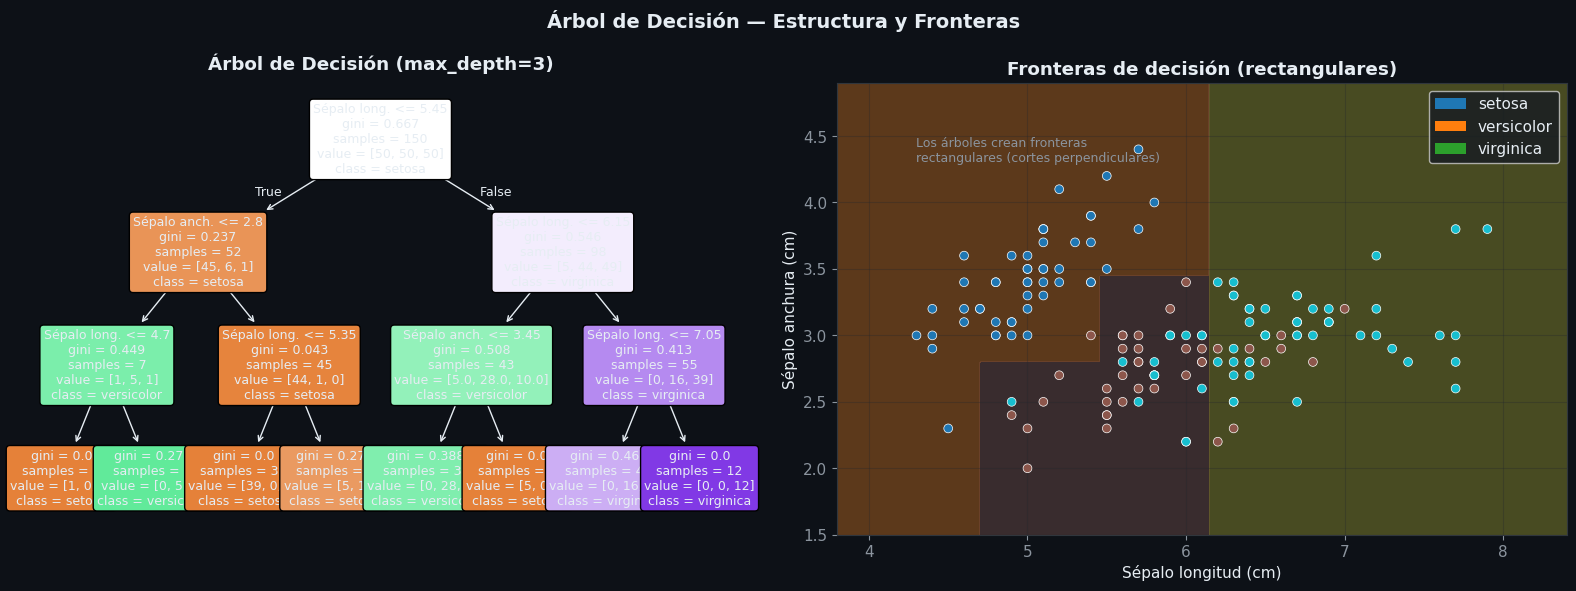

Guardado: 06_arbol_decision.png


In [7]:
from sklearn.datasets import load_iris

iris = load_iris()
X_iris = iris.data[:, :2]  # solo 2 features para visualizar
y_iris = iris.target

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Árbol depth=3
dt = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_iris, y_iris)

# Left: tree structure
ax = axes[0]
plot_tree(dt, feature_names=['Sépalo long.', 'Sépalo anch.'],
          class_names=iris.target_names,
          filled=True, rounded=True, ax=ax,
          fontsize=9)
ax.set_title('Árbol de Decisión (max_depth=3)', color=WHITE, fontweight='bold', pad=10)
ax.set_facecolor(PANEL_BG)

# Right: decision boundaries
ax = axes[1]
xx, yy = np.meshgrid(np.linspace(X_iris[:,0].min()-0.5, X_iris[:,0].max()+0.5, 300),
                     np.linspace(X_iris[:,1].min()-0.5, X_iris[:,1].max()+0.5, 300))
Z = dt.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax.contourf(xx, yy, Z, alpha=0.3, cmap='tab10', levels=[-0.5,0.5,1.5,2.5])
scatter = ax.scatter(X_iris[:,0], X_iris[:,1], c=y_iris, cmap='tab10', 
                    edgecolors='white', s=40, linewidths=0.5, zorder=4)
ax.set_xlabel('Sépalo longitud (cm)')
ax.set_ylabel('Sépalo anchura (cm)')
ax.set_title('Fronteras de decisión (rectangulares)', color=WHITE, fontweight='bold')
ax.text(X_iris[:,0].min(), X_iris[:,1].max()*0.98,
        'Los árboles crean fronteras\nrectangulares (cortes perpendiculares)',
        color=GRAY, fontsize=9)
ax.grid(True, alpha=0.3)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=n) for c, n in 
                   zip(['#1f77b4','#ff7f0e','#2ca02c'], iris.target_names)]
ax.legend(handles=legend_elements, facecolor=PANEL_BG, labelcolor=WHITE)

plt.suptitle('Árbol de Decisión — Estructura y Fronteras', color=WHITE, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/06_arbol_decision.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 06_arbol_decision.png')

## Gráfico 7 — Overfitting vs Underfitting vs Buen ajuste

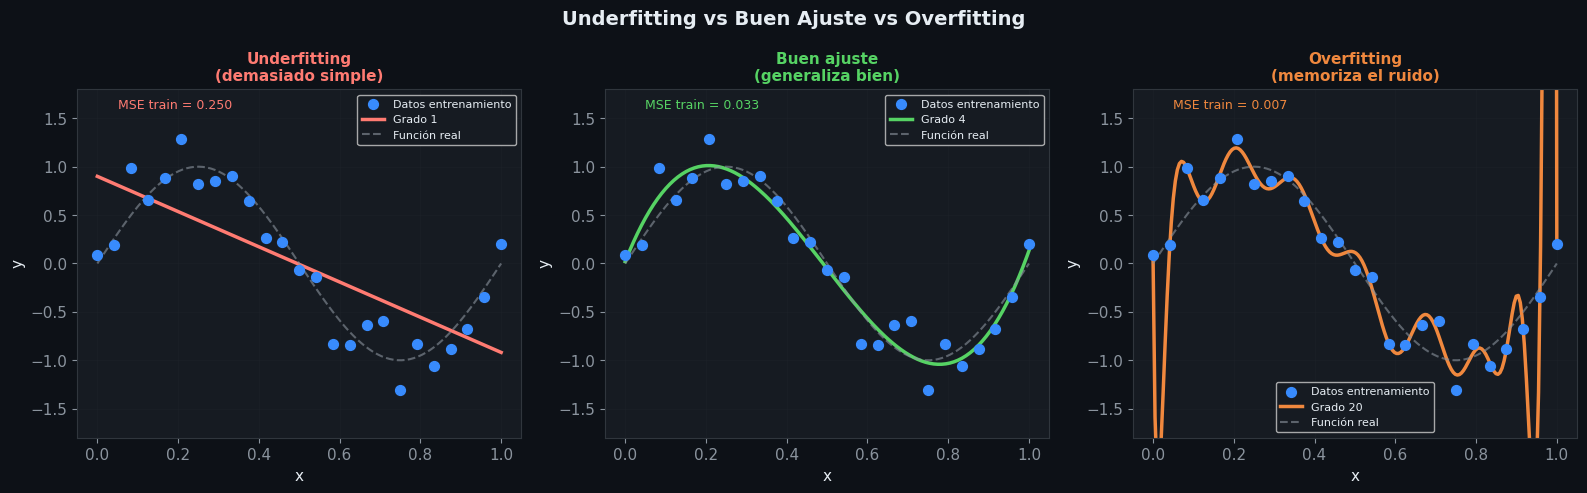

Guardado: 07_overfitting.png


In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

np.random.seed(5)
X_poly = np.linspace(0, 1, 25)
y_poly = np.sin(2 * np.pi * X_poly) + np.random.normal(0, 0.2, 25)
X_test_poly = np.linspace(0, 1, 200)

degrees = [1, 4, 20]
labels = ['Underfitting\n(demasiado simple)', 'Buen ajuste\n(generaliza bien)', 'Overfitting\n(memoriza el ruido)']
colors_line = [RED, GREEN, ORANGE]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, deg, lbl, lc in zip(axes, degrees, labels, colors_line):
    pipe = make_pipeline(PolynomialFeatures(deg), LinearRegression())
    pipe.fit(X_poly.reshape(-1,1), y_poly)
    y_test_pred = pipe.predict(X_test_poly.reshape(-1,1))
    y_train_pred = pipe.predict(X_poly.reshape(-1,1))
    
    train_err = np.mean((y_poly - y_train_pred)**2)
    
    ax.scatter(X_poly, y_poly, color=BLUE, s=50, zorder=4, label='Datos entrenamiento')
    ax.plot(X_test_poly, y_test_pred, color=lc, linewidth=2.5, label=f'Grado {deg}')
    ax.plot(X_test_poly, np.sin(2*np.pi*X_test_poly), color=GRAY, 
           linestyle='--', linewidth=1.5, alpha=0.6, label='Función real')
    
    ax.set_title(lbl, color=lc, fontweight='bold', fontsize=11)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_ylim(-1.8, 1.8)
    ax.legend(facecolor=PANEL_BG, labelcolor=WHITE, fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.text(0.05, 1.6, f'MSE train = {train_err:.3f}', color=lc, fontsize=9)

plt.suptitle('Underfitting vs Buen Ajuste vs Overfitting', color=WHITE, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/07_overfitting.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 07_overfitting.png')